# 13. Granularity check: dunnhumby and Online Retail II

The two main datasets only rank 17 categories. Is "popularity is hard to beat" a property of the methods, or of the small candidate set? The same baselines are run on datasets with many more items:
- dunnhumby, commodity level: 304 items
- dunnhumby, sub-commodity level: 2,329 items
- Online Retail II: 4,618 SKUs

The two dunnhumby versions use the same transactions; only the item level changes. Only baselines are run (no LightGCN). The history baselines use purchase counts here, because customers rebuy the same items often at this granularity.

Inputs: `clean/` from notebooks 11 and 12, and the EuroMart and Retail POS snapshots used in notebook 7.

In [1]:
import json, time, pathlib, hashlib
import numpy as np
import pandas as pd
import scipy.sparse as sp

SUB   = pathlib.Path.cwd()                    # .../SC4020-DataMining/Submission
REPO  = SUB.parent
CLEAN = SUB / "clean"                         # written by notebooks 11 and 12
BIG   = SUB / "big"                           # snapshots built below (large, not committed)
OUT   = SUB / "outputs" / "granularity"; OUT.mkdir(parents=True, exist_ok=True)
PUBLISHED = REPO / "results" / "nicholas lightgcn" / "granularity"
SLUGS = ["dunnhumby_commodity", "dunnhumby", "online_retail_ii"]
print(sorted(p.name for p in CLEAN.glob("*__metadata.json")))

['dunnhumby__metadata.json', 'online_retail_ii__metadata.json']


## 1. dunnhumby at commodity level
The cleaned transactions are re-aggregated to `COMMODITY_DESC`. Customers, periods and split are unchanged.

In [2]:
SRC, DST = CLEAN, CLEAN
OLD, NEW = "dunnhumby", "dunnhumby_commodity"

txn = pd.read_csv(SRC / f"{OLD}__transactions_clean.csv",
                  usecols=["basket_id", "customer_idx", "period_idx",
                           "item_idx", "parent_commodity", "parent_department",
                           "quantity", "revenue"])
sku = pd.read_csv(SRC / f"{OLD}__interactions_monthly.csv")
cal = pd.read_csv(SRC / f"{OLD}__calendar.csv")
cmap = pd.read_csv(SRC / f"{OLD}__customer_id_map.csv")
imap_old = pd.read_csv(SRC / f"{OLD}__item_id_map.csv")

# ---- commodity registry: alphabetical, contiguous 0..N-1 (same convention as the SKU map)
commodities = sorted(txn.parent_commodity.unique())
cidx = {c: i for i, c in enumerate(commodities)}
txn["commodity_idx"] = txn.parent_commodity.map(cidx).astype(np.int64)

# department per commodity: the unique one, or MIXED if a commodity spans several
dept = (txn.groupby("parent_commodity").parent_department
           .agg(lambda s: s.iloc[0] if s.nunique() == 1 else "MIXED"))
imap = pd.DataFrame({
    "item_idx": np.arange(len(commodities), dtype=np.int64),
    "item_label": commodities,
    "description": commodities,
    "parent_department": [dept[c] for c in commodities],
    "parent_commodity": commodities,           # self at this level
})

# ---- interactions: recomputed from the log, so n_baskets is a true distinct count
agg = (txn.groupby(["period_idx", "customer_idx", "commodity_idx"], as_index=False)
          .agg(n_lineitems=("basket_id", "size"),
               n_baskets=("basket_id", "nunique"),
               total_quantity=("quantity", "sum"),
               total_revenue=("revenue", "sum")))
agg = agg.rename(columns={"commodity_idx": "item_idx"})
agg["log_quantity"] = np.log1p(agg.total_quantity).round(4)
agg["weight"] = 1
agg = agg[["period_idx", "customer_idx", "item_idx", "n_lineitems", "n_baskets",
           "total_quantity", "total_revenue", "log_quantity", "weight"]]
agg = agg.sort_values(["period_idx", "customer_idx", "item_idx"]).reset_index(drop=True)

# ---------------------------------------------------------------- validation
def chk(name, ok, detail=""):
    print(f"  {'OK  ' if ok else 'FAIL'} {name}{(' — ' + detail) if detail else ''}")
    assert ok, name

print("validation:")
chk("line items conserved", int(agg.n_lineitems.sum()) == int(sku.n_lineitems.sum()),
    f"{int(agg.n_lineitems.sum()):,} == {int(sku.n_lineitems.sum()):,}")
chk("line items == transaction rows", int(agg.n_lineitems.sum()) == len(txn),
    f"{len(txn):,}")
chk("quantity conserved", int(agg.total_quantity.sum()) == int(sku.total_quantity.sum()),
    f"{int(agg.total_quantity.sum()):,}")
chk("revenue conserved", abs(agg.total_revenue.sum() - sku.total_revenue.sum()) < 0.01,
    f"{agg.total_revenue.sum():,.2f}")
chk("same customers", set(agg.customer_idx) == set(sku.customer_idx),
    f"{agg.customer_idx.nunique():,}")
chk("same periods", sorted(agg.period_idx.unique()) == sorted(sku.period_idx.unique()),
    f"{agg.period_idx.nunique()} periods")
chk("item index contiguous from 0", agg.item_idx.min() == 0 and
    agg.item_idx.max() == len(commodities) - 1, f"0..{len(commodities)-1}")
chk("baskets not inflated", int(agg.n_baskets.sum()) <= int(sku.n_baskets.sum()),
    f"{int(agg.n_baskets.sum()):,} <= {int(sku.n_baskets.sum()):,} (collapse dedups)")
chk("no duplicate rows",
    not agg.duplicated(["period_idx", "customer_idx", "item_idx"]).any())
chk("weight binary", set(agg.weight.unique()) == {1})
chk("every commodity has a department", imap.parent_department.notna().all())

e_old = sku.groupby(["customer_idx", "item_idx"]).ngroups
e_new = agg.groupby(["customer_idx", "item_idx"]).ngroups
print(f"\n  unique customer-item edges : {e_old:,} (sub-commodity) -> {e_new:,} (commodity)")
print(f"  item nodes                 : {len(imap_old):,} -> {len(imap):,}")
print(f"  density                    : "
      f"{e_old/(cmap.shape[0]*len(imap_old)):.4f} -> {e_new/(cmap.shape[0]*len(imap)):.4f}")
print(f"  rows in interactions table : {len(sku):,} -> {len(agg):,}")

# ---------------------------------------------------------------- write
DST.mkdir(parents=True, exist_ok=True)
agg.to_csv(DST / f"{NEW}__interactions_monthly.csv", index=False)
imap.to_csv(DST / f"{NEW}__item_id_map.csv", index=False)
cal.to_csv(DST / f"{NEW}__calendar.csv", index=False)
cmap.to_csv(DST / f"{NEW}__customer_id_map.csv", index=False)
meta = json.load(open(SRC / f"{OLD}__metadata.json"))
meta.update({
    "dataset": "dunnhumby The Complete Journey (commodity-level granularity control)",
    "slug": NEW, "item_level": "COMMODITY_DESC",
    "item_meaning": "product commodity category (parent of SUB_COMMODITY_DESC)",
    "n_items": len(imap), "item_node_offset": int(cmap.shape[0]),
    "n_edges": int(e_new),
    "derived_from": f"{OLD} cleaned artifacts; re-aggregated from the cleaned "
                    "transaction log, customers / periods / calendar / split unchanged",
})
json.dump(meta, open(DST / f"{NEW}__metadata.json", "w"), indent=2)
print(f"\nwrote 5 artifacts to {DST}")


validation:
  OK   line items conserved — 2,300,921 == 2,300,921
  OK   line items == transaction rows — 2,300,921
  OK   quantity conserved — 3,020,331
  OK   revenue conserved — 6,668,029.40


  OK   same customers — 2,492
  OK   same periods — 21 periods
  OK   item index contiguous from 0 — 0..303
  OK   baskets not inflated — 1,692,458 <= 1,951,422 (collapse dedups)
  OK   no duplicate rows
  OK   weight binary
  OK   every commodity has a department



  unique customer-item edges : 568,145 (sub-commodity) -> 270,112 (commodity)
  item nodes                 : 2,329 -> 304
  density                    : 0.0979 -> 0.3566
  rows in interactions table : 1,541,479 -> 1,164,752



wrote 5 artifacts to clean


## 2. Snapshots
Built with the same rules as the shared builder: the graph uses earlier periods only, and eligible customers are those seen before and active in the period. The pair-level history matrices are stored sparse, since only about 2% of entries are non-zero.

In [3]:
def build(slug, data_dir, out_dir, keep_floats=False):
    data_dir, out_dir = pathlib.Path(data_dir), pathlib.Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    meta = json.load(open(data_dir/f"{slug}__metadata.json"))
    cal = pd.read_csv(data_dir/f"{slug}__calendar.csv")
    nC, nI, T = int(meta["n_customers"]), int(meta["n_items"]), int(meta["n_periods"])
    df = pd.read_csv(data_dir/f"{slug}__interactions_monthly.csv")
    split_of = dict(zip(cal.period_idx, cal.split))

    c = df.customer_idx.to_numpy(np.int64); i = df.item_idx.to_numpy(np.int64)
    t = df.period_idx.to_numpy(np.int64)
    li = df.n_lineitems.to_numpy(np.float64); bk = df.n_baskets.to_numpy(np.float64)
    qt = df.total_quantity.to_numpy(np.float64); rv = df.total_revenue.to_numpy(np.float64)

    # dense pair ids over the universe of (customer, item) pairs that ever occur
    pid_raw = c * nI + i
    uniq, pid = np.unique(pid_raw, return_inverse=True)
    P = len(uniq)
    pc, pi = uniq // nI, uniq % nI

    acc = {k: np.zeros(P) for k in ("li", "bk", "qt", "rv")}
    last = np.full(P, -1, np.int64)
    seen = np.zeros(P, bool)
    cust_first = np.full(nC, -1, np.int64)
    cust_periods = [set() for _ in range(nC)]

    by_t = {p: np.where(t == p)[0] for p in range(T)}
    index_rows = []
    for tgt in range(T):
        hist_any = seen.any()
        # ---------- category (item) features over full history ----------
        cat_raw = np.zeros((nI, 7), np.float32)
        cat_deg = np.zeros(nI, np.int32)
        if hist_any:
            s = seen
            it_li = np.bincount(pi[s], acc["li"][s], minlength=nI)
            it_bk = np.bincount(pi[s], acc["bk"][s], minlength=nI)
            it_qt = np.bincount(pi[s], acc["qt"][s], minlength=nI)
            it_rv = np.bincount(pi[s], acc["rv"][s], minlength=nI)
            it_uc = np.bincount(pi[s], minlength=nI).astype(np.float64)   # distinct customers
            it_last = np.full(nI, -1, np.int64)
            np.maximum.at(it_last, pi[s], last[s])
            total_rows = it_li.sum()
            fresh = np.where(it_last >= 0, 1.0/(1.0+np.maximum(tgt-it_last-1, 0)), 0.0)
            cat_raw[:, 0] = np.log1p(it_li); cat_raw[:, 1] = np.log1p(it_bk)
            cat_raw[:, 2] = np.log1p(it_qt); cat_raw[:, 3] = np.log1p(it_rv)
            cat_raw[:, 4] = np.log1p(it_uc)
            cat_raw[:, 5] = it_li/total_rows if total_rows else 0.0
            cat_raw[:, 6] = fresh
            cat_deg = it_uc.astype(np.int32)
        # ---------- graph ----------
        edge = np.vstack([pc[seen], pi[seen]]).astype(np.int64) if hist_any else np.empty((2,0),np.int64)
        # ---------- eligibility + labels ----------
        rows_t = by_t[tgt]
        active = np.unique(c[rows_t])
        hist_cust = np.unique(pc[seen]) if hist_any else np.empty(0, np.int64)
        elig = np.intersect1d(active, hist_cust, assume_unique=False)
        row_of = -np.ones(nC, np.int64); row_of[elig] = np.arange(len(elig))
        R = len(elig)
        lab = np.zeros((R, nI), np.uint8)
        if R:
            m = row_of[c[rows_t]] >= 0
            lab[row_of[c[rows_t][m]], i[rows_t][m]] = 1
        # ---------- pair-history matrices, sparse ----------
        if R and hist_any:
            keep = seen & (row_of[pc] >= 0)
            rr = row_of[pc[keep]]; cc = pi[keep]
            cnt = sp.csr_matrix((acc["li"][keep], (rr, cc)), shape=(R, nI))
            ordc = sp.csr_matrix((acc["bk"][keep], (rr, cc)), shape=(R, nI))
            prev = sp.csr_matrix(((last[keep] == tgt-1).astype(np.uint8), (rr, cc)), shape=(R, nI))
            mask = sp.csr_matrix((np.ones(keep.sum(), np.uint8), (rr, cc)), shape=(R, nI))
            frs = sp.csr_matrix((1.0/(1.0+np.maximum(tgt-last[keep]-1,0)), (rr, cc)), shape=(R, nI))
        else:
            z = sp.csr_matrix((R, nI))
            cnt = ordc = prev = mask = frs = z
        payload = dict(
            edge_index_bipartite=edge, labels=lab,
            eligible_customer_idx=elig.astype(np.int64),
            category_features_raw=cat_raw, category_history_degree=cat_deg,
            n_customers=np.int64(nC), n_categories=np.int64(nI),
            cnt_data=cnt.data.astype(np.float32), cnt_indices=cnt.indices, cnt_indptr=cnt.indptr,
            prev_data=prev.data.astype(np.uint8), prev_indices=prev.indices, prev_indptr=prev.indptr,
            mask_data=mask.data.astype(np.uint8), mask_indices=mask.indices, mask_indptr=mask.indptr,
            ord_data=ordc.data.astype(np.float32), ord_indices=ordc.indices, ord_indptr=ordc.indptr,
            frs_data=frs.data.astype(np.float32), frs_indices=frs.indices, frs_indptr=frs.indptr,
        )
        p = out_dir/f"P{tgt:02d}.npz"
        np.savez_compressed(p, **payload)
        h = hashlib.sha256(p.read_bytes()).hexdigest()
        index_rows.append(dict(dataset=slug, period=f"P{tgt:02d}", split=split_of[tgt],
                               eligible_customers=R, positive_pairs=int(lab.sum()),
                               candidate_pairs=int(lab.size), unique_edges=int(edge.shape[1]),
                               repeated_positive_pairs=int(mask.multiply(lab).sum()) if R else 0,
                               prev_period_positive_pairs=int(prev.multiply(lab).sum()) if R else 0,
                               sha256=h))
        # ---------- advance accumulators to include period tgt ----------
        r = by_t[tgt]
        np.add.at(acc["li"], pid[r], li[r]); np.add.at(acc["bk"], pid[r], bk[r])
        np.add.at(acc["qt"], pid[r], qt[r]); np.add.at(acc["rv"], pid[r], rv[r])
        np.maximum.at(last, pid[r], tgt)
        seen[pid[r]] = True
    idx = pd.DataFrame(index_rows); idx.to_csv(out_dir/"snapshot_index.csv", index=False)
    y = np.concatenate([np.load(out_dir/f"P{p:02d}.npz")["labels"] for p in range(T)
                        if split_of[p]=="train" and np.load(out_dir/f"P{p:02d}.npz")["labels"].size])
    pos=int(y.sum()); cand=int(y.size)
    json.dump(dict(primary_scalar_pos_weight=float((cand-pos)/pos),
                   train_positive_prevalence=float(pos/cand),
                   n_customers=nC, n_items=nI, n_periods=T),
              open(out_dir/"loss_diagnostics.json","w"), indent=2)
    return idx



for slug in SLUGS:
    t0 = time.time(); idx = build(slug, CLEAN, BIG / "snap" / slug)
    print(f"{slug}: {len(idx)} snapshots in {time.time()-t0:.0f}s")
    print(idx.groupby("split")[["eligible_customers", "positive_pairs"]].sum().to_string())

dunnhumby_commodity: 21 snapshots in 11s
       eligible_customers  positive_pairs
split                                    
test                 6020          173918
train               27140          762907
val                  6016          168133


dunnhumby: 21 snapshots in 20s
       eligible_customers  positive_pairs
split                                    
test                 6020          231383
train               27140         1010316
val                  6016          221753


online_retail_ii: 24 snapshots in 8s
       eligible_customers  positive_pairs
split                                    
test                 4506          140922
train               11142          318477
val                  3417           86844


## 3. Loading

In [4]:
def _csr(z, p, shape, dt):
    return sp.csr_matrix((z[f"{p}_data"].astype(dt), z[f"{p}_indices"], z[f"{p}_indptr"]), shape=shape)

def load_period(path):
    z = np.load(path, allow_pickle=True)
    nC, nI = int(z["n_customers"]), int(z["n_categories"])
    lab = z["labels"]; R = lab.shape[0]
    return dict(labels=lab, eligible_customer_idx=z["eligible_customer_idx"],
                category_features_raw=z["category_features_raw"],
                n_customers=nC, n_categories=nI,
                cnt=_csr(z, "cnt", (R, nI), np.float64),
                prev=_csr(z, "prev", (R, nI), np.float64),
                mask=_csr(z, "mask", (R, nI), np.float64))

def load_dataset(slug):
    d = BIG / "snap" / slug
    idx = pd.read_csv(d / "snapshot_index.csv")
    loss = json.load(open(d / "loss_diagnostics.json"))
    out = {}
    for s in ("train", "val", "test"):
        ps = []
        for _, r in idx[idx.split == s].iterrows():
            p = load_period(d / f"{r['period']}.npz"); p["_name"] = r["period"]; ps.append(p)
        out[s] = ps
    out["meta"] = dict(n_customers=loss["n_customers"], n_categories=loss["n_items"],
                       prevalence=loss["train_positive_prevalence"])
    return out

### Baselines
The same five baselines as in notebook 7, scored by rank.

In [5]:
def seeded_rng(*parts):
    h = hashlib.sha256("|".join(str(p) for p in parts).encode()).digest()
    return np.random.default_rng(int.from_bytes(h[:8], "little"))

def rank_score(*keys):
    R, C = keys[0].shape
    order = np.lexsort(tuple(-k for k in reversed(keys)), axis=1)
    out = np.empty((R, C), dtype=np.float64)
    np.put_along_axis(out, order, np.arange(C, 0, -1, dtype=np.float64)[None, :].repeat(R, 0), axis=1)
    return out

BASELINES = ["Random", "GlobalPopularity", "PersonalHistory", "RepeatLastPeriod", "PopularityPersonalBlend"]

def baseline_scores(name, p, slug, seed=0):
    R = len(p["eligible_customer_idx"]); C = p["n_categories"]
    pop = p["category_features_raw"][:, 0].astype(np.float64)
    if name == "Random":
        return seeded_rng(slug, p["_name"], name, seed).random((R, C))
    POP = np.tile(pop, (R, 1))
    if name == "GlobalPopularity":
        return rank_score(POP)
    if name == "PersonalHistory":
        return rank_score(p["cnt"].toarray(), POP)
    if name == "RepeatLastPeriod":
        return rank_score(p["prev"].toarray(), p["cnt"].toarray(), POP)
    if name == "PopularityPersonalBlend":
        pn = pop / (pop.max() or 1.0); ph = p["cnt"].toarray()
        rs = ph.max(1, keepdims=True); ph = ph / np.where(rs > 0, rs, 1.0)
        return rank_score(0.5 * np.tile(pn, (R, 1)) + 0.5 * ph, POP)
    raise ValueError(name)

### Metrics and repeat / novel split
A recommended item is a repeat if the customer bought it in an earlier period and novel otherwise. Both recalls come from the same ranking.

In [6]:
_LOG2 = np.log2(np.arange(2, 64))

def average_precision(score, y):
    """Micro average precision with tied scores grouped (as in scikit-learn), so the
    result does not depend on the order of tied rows, e.g. the identical scores that
    GlobalPopularity gives every customer."""
    o = np.argsort(-score, kind="stable")
    s, y = score[o], y[o].astype(np.float64)
    P = y.sum()
    if P == 0:
        return np.nan
    last = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]   # end of each block of tied scores
    tp = np.cumsum(y)[last]
    prec, rec = tp / (last + 1), tp / P
    return float(np.sum(np.diff(np.r_[0.0, rec]) * prec))

def ranking_metrics(scores, labels, ks=(3, 5, 10)):
    order = np.argsort(-scores, axis=1, kind="stable")
    rel = np.take_along_axis(labels, order, axis=1).astype(np.float64)
    npos = labels.sum(axis=1).astype(np.float64)
    out = {}
    for k in ks:
        r = rel[:, :k]; hits = r.sum(axis=1); disc = 1.0 / _LOG2[:k]
        dcg = (r * disc).sum(axis=1)
        idcg = np.array([disc[:m].sum() if m > 0 else 1.0 for m in np.minimum(npos, k).astype(int)])
        out[f"Recall@{k}"] = float(np.mean(np.where(npos > 0, hits / np.maximum(npos, 1), 0.0)))
        out[f"NDCG@{k}"]   = float(np.mean(np.where(idcg > 0, dcg / idcg, 0.0)))
    out["PR-AUC"] = average_precision(scores.ravel(), labels.ravel())
    return out

def repeat_novel(S, Y, M, ks=(3, 5, 10)):
    """M = historical pair mask. Repeat / novel positives are read off the same unchanged ranking."""
    out = {}
    order = np.argsort(-S, axis=1, kind="stable")
    relY = np.take_along_axis(Y, order, axis=1).astype(bool)
    relM = np.take_along_axis(M, order, axis=1).astype(bool)
    rep_pos = (Y.astype(bool) & M.astype(bool)).sum(1); nov_pos = (Y.astype(bool) & ~M.astype(bool)).sum(1)
    for k in ks:
        rh = (relY[:, :k] & relM[:, :k]).sum(1); nh = (relY[:, :k] & ~relM[:, :k]).sum(1)
        out[f"repeated_recall@{k}"] = float(np.mean(rh[rep_pos > 0] / rep_pos[rep_pos > 0])) if (rep_pos > 0).any() else np.nan
        out[f"novel_recall@{k}"] = float(np.mean(nh[nov_pos > 0] / nov_pos[nov_pos > 0])) if (nov_pos > 0).any() else np.nan
    out["repeated_positive_pairs"] = int(rep_pos.sum()); out["novel_positive_pairs"] = int(nov_pos.sum())
    return out

## 4. Run on all five datasets
The two 17-category datasets go through the same code, using the snapshots from notebook 7.

In [7]:
def load_team_period(path):
    """A team snapshot (dense pair arrays) in the same form as the sparse loader above."""
    z = np.load(path, allow_pickle=True)
    cnt = z["eligible_history_interaction_count"] if "eligible_history_interaction_count" in z.files else z["eligible_history_pair_mask"]
    return dict(labels=z["labels"], eligible_customer_idx=z["eligible_customer_idx"],
                category_features_raw=z["category_features_raw"],
                n_customers=int(z["customer_features"].shape[0]), n_categories=int(z["category_features"].shape[0]),
                cnt=sp.csr_matrix(cnt.astype(np.float64)), prev=sp.csr_matrix(z["eligible_previous_month_mask"].astype(np.float64)),
                mask=sp.csr_matrix(z["eligible_history_pair_mask"].astype(np.float64)))

TEAM = {"euromart_quarterly": (SUB / "data" / "euromart_quarterly", ["2014Q2", "2014Q3", "2014Q4"]),
        "retail_pos_monthly": (REPO / "graph_data" / "retail_pos" / "monthly", ["2024-11", "2024-12"])}

def test_periods(slug):
    if slug in TEAM:
        d, names = TEAM[slug]
        return [dict(load_team_period(d / f"{n}.npz"), _name=n) for n in names]
    return load_dataset(slug)["test"]

rows = []
for slug in list(TEAM) + SLUGS:
    t0 = time.time(); tp = [p for p in test_periods(slug) if len(p["eligible_customer_idx"])]
    Y = np.vstack([p["labels"] for p in tp]); M = np.vstack([p["mask"].toarray() for p in tp])
    for name in BASELINES:
        S_ = np.vstack([baseline_scores(name, p, slug) for p in tp])
        m = ranking_metrics(S_, Y); m.update(repeat_novel(S_, Y, M))
        m.update(dataset=slug, method=name, n_items=tp[0]["n_categories"], n_customer_periods=S_.shape[0])
        rows.append(m)
    print(f"{slug}: {len(BASELINES)} baselines in {time.time()-t0:.0f}s")

ALL5 = pd.DataFrame(rows)
cols = ["dataset", "method", "n_items", "n_customer_periods", "NDCG@3", "NDCG@5", "NDCG@10", "Recall@10", "PR-AUC",
        "repeated_recall@3", "repeated_recall@5", "repeated_recall@10", "novel_recall@3", "novel_recall@5",
        "novel_recall@10", "repeated_positive_pairs", "novel_positive_pairs"]
ALL5[cols].to_csv(OUT / "baselines_all5_repeat_novel.csv", index=False)
ALL5[["dataset", "n_items", "method", "NDCG@10", "repeated_recall@10", "novel_recall@10"]].round(4)

euromart_quarterly: 5 baselines in 0s
retail_pos_monthly: 5 baselines in 0s


dunnhumby_commodity: 5 baselines in 3s


dunnhumby: 5 baselines in 44s


online_retail_ii: 5 baselines in 67s


,dataset,n_items,method,NDCG@10,repeated_recall@10,novel_recall@10
0,euromart_quarterly,17,Random,0.3300,0.5896,0.5813
1,euromart_quarterly,17,GlobalPopularity,0.4773,0.8455,0.6398
2,euromart_quarterly,17,PersonalHistory,0.4404,0.9929,0.4899
3,euromart_quarterly,17,RepeatLastPeriod,0.4355,0.9933,0.4899
4,euromart_quarterly,17,PopularityPersonalBlend,0.4411,0.9929,0.4930
5,retail_pos_monthly,17,Random,0.4340,0.5910,0.5642
6,retail_pos_monthly,17,GlobalPopularity,0.6291,0.8595,0.5965
7,retail_pos_monthly,17,PersonalHistory,0.5713,0.9612,0.2336
8,retail_pos_monthly,17,RepeatLastPeriod,0.5678,0.9605,0.2336
9,retail_pos_monthly,17,PopularityPersonalBlend,0.5730,0.9633,0.2360


In [8]:
# Reproduction check against the committed table (PR-AUC is compared only where the committed value is tie-aware)
pub = pd.read_csv(PUBLISHED / "baselines_all5_repeat_novel.csv")
m = ALL5.merge(pub, on=["dataset", "method"], suffixes=("_nb", "_pub"))
for c in ["NDCG@5", "NDCG@10", "Recall@10", "repeated_recall@10", "novel_recall@10"]:
    print(f"{c:20s} max |difference| = {float((m[c + '_nb'] - m[c + '_pub']).abs().max()):.2e}")
print("rows matched:", len(m), "of", len(pub))

NDCG@5               max |difference| = 8.33e-17
NDCG@10              max |difference| = 8.33e-17
Recall@10            max |difference| = 9.71e-17
repeated_recall@10   max |difference| = 1.11e-16
novel_recall@10      max |difference| = 9.89e-17
rows matched: 25 of 25


## 5. Ladder table
The quantity to read is the gap between the best history baseline and popularity; raw scores are not comparable across rows.

In [9]:
NAMES = {"euromart_quarterly": "EuroMart (quarterly)", "retail_pos_monthly": "Retail POS",
         "dunnhumby_commodity": "dunnhumby (commodity)", "dunnhumby": "dunnhumby (sub-commodity)",
         "online_retail_ii": "Online Retail II"}
LADDER = (ALL5.pivot_table(index=["dataset", "n_items"], columns="method", values="NDCG@10").reset_index()
          [["dataset", "n_items", "GlobalPopularity", "PersonalHistory", "RepeatLastPeriod"]])
LADDER["best_personalised_minus_popularity"] = LADDER[["PersonalHistory", "RepeatLastPeriod"]].max(axis=1) - LADDER["GlobalPopularity"]
LADDER["dataset"] = LADDER.dataset.map(NAMES)
LADDER = LADDER.sort_values(["n_items", "dataset"]).reset_index(drop=True)
LADDER.to_csv(OUT / "table23_ladder_ndcg10.csv", index=False)
LADDER.round(4)

method,dataset,n_items,GlobalPopularity,PersonalHistory,RepeatLastPeriod,best_personalised_minus_popularity
0,EuroMart (quarterly),17,0.4773,0.4404,0.4355,-0.0369
1,Retail POS,17,0.6291,0.5713,0.5678,-0.0578
2,dunnhumby (commodity),304,0.5356,0.6304,0.6268,0.0947
3,dunnhumby (sub-commodity),2329,0.3623,0.5102,0.5183,0.1560
4,Online Retail II,4618,0.0959,0.3228,0.3213,0.2269


The sign of the gap flips between 17 and 304 items and then keeps growing: at 4,618 SKUs personal history is ahead by about 0.23 NDCG@10.

In [10]:
nov = ALL5.pivot_table(index=["dataset", "n_items"], columns="method", values="novel_recall@10")
nov["pop_over_personal"] = nov["GlobalPopularity"] / nov["PersonalHistory"]
rep = ALL5.pivot_table(index=["dataset", "n_items"], columns="method", values="repeated_recall@10")
print("novel recall@10 (popularity / personal history):")
display(nov[["GlobalPopularity", "PersonalHistory", "pop_over_personal"]].sort_index(level=1).round(4))
print("repeat recall@10:")
display(rep[["GlobalPopularity", "PersonalHistory"]].sort_index(level=1).round(4))

novel recall@10 (popularity / personal history):


,method,GlobalPopularity,PersonalHistory,pop_over_personal
dataset,n_items,,,
euromart_quarterly,17,0.6398,0.4899,1.3058
retail_pos_monthly,17,0.5965,0.2336,2.5533
dunnhumby_commodity,304,0.0249,0.0007,33.3340
dunnhumby,2329,0.0160,0.0003,48.8123
online_retail_ii,4618,0.0120,0.0005,24.0011


repeat recall@10:


,method,GlobalPopularity,PersonalHistory
dataset,n_items,,
euromart_quarterly,17,0.8455,0.9929
retail_pos_monthly,17,0.8595,0.9612
dunnhumby_commodity,304,0.2252,0.3029
dunnhumby,2329,0.1407,0.2392
online_retail_ii,4618,0.0646,0.3556


Repeat buying dominates at fine granularity. On Online Retail II, personal history recovers about 36% of repeat positives in its top 10, against about 6.5% for popularity. New items are hard for every method and hardest for the personalised ones, so popularity is 24-49 times better on novel items in the three larger datasets. The figure below shows both effects.

## 6. Figure
Left: which method wins as the number of items grows. Right: recall on novel items for popularity and personal history (log scale).

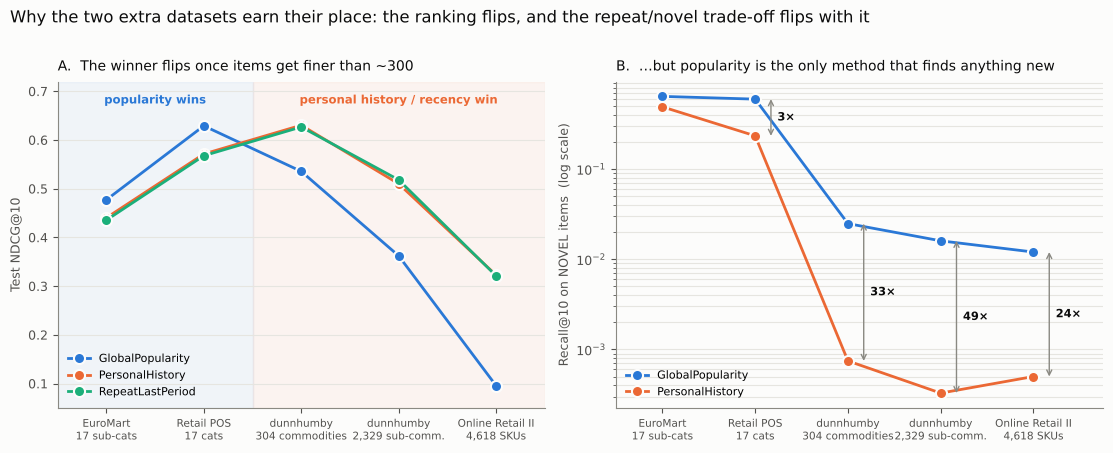

In [11]:
import matplotlib.pyplot as plt

S1,S2,S3,S4="#2a78d6","#eb6834","#1baf7a","#eda100"
INK,INK2,MUTED,SURF,GRID="#0b0b0b","#52514e","#8a8982","#fcfcfb","#e6e5e0"
plt.rcParams.update({"figure.facecolor":SURF,"axes.facecolor":SURF,"font.size":9,
    "axes.edgecolor":MUTED,"axes.labelcolor":INK2,"xtick.color":INK2,"ytick.color":INK2,
    "axes.spines.top":False,"axes.spines.right":False,"font.family":"DejaVu Sans"})
FIG = OUT.parent / "figures"; FIG.mkdir(parents=True, exist_ok=True)
G5 = pd.read_csv(OUT / "baselines_all5_repeat_novel.csv")

# who wins as the item count grows, and novel-item recall
order=["euromart_quarterly","retail_pos_monthly","dunnhumby_commodity","dunnhumby","online_retail_ii"]
lab=["EuroMart\n17 sub-cats","Retail POS\n17 cats","dunnhumby\n304 commodities","dunnhumby\n2,329 sub-comm.","Online Retail II\n4,618 SKUs"]
g=lambda m,c:[G5[(G5.dataset==ds)&(G5.method==m)][c].iloc[0] for ds in order]
x=np.arange(5)

fig,axes=plt.subplots(1,2,figsize=(11.2,4.4))
# --- A: who wins overall ---
ax=axes[0]
for m,c,l in [("GlobalPopularity",S1,"GlobalPopularity"),("PersonalHistory",S2,"PersonalHistory"),
              ("RepeatLastPeriod",S3,"RepeatLastPeriod")]:
    ax.plot(x,g(m,"NDCG@10"),"-o",color=c,lw=2,ms=8,mec=SURF,mew=1.5,label=l,zorder=3)
ax.axvspan(-0.5,1.5,color="#2a78d6",alpha=0.055,zorder=0)
ax.axvspan(1.5,4.5,color="#eb6834",alpha=0.055,zorder=0)
ax.text(0.5,0.675,"popularity wins",ha="center",fontsize=8.4,color=S1,fontweight="bold")
ax.text(3.0,0.675,"personal history / recency win",ha="center",fontsize=8.4,color=S2,fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(lab,fontsize=7.6); ax.set_xlim(-0.5,4.5); ax.set_ylim(0.05,0.72)
ax.grid(axis="y",color=GRID,lw=0.8); ax.set_axisbelow(True)
ax.set_ylabel("Test NDCG@10",fontsize=9)
ax.set_title("A.  The winner flips once items get finer than ~300",fontsize=10,color=INK,pad=8,loc="left")
ax.legend(fontsize=8,frameon=False,loc="lower left")
# --- B: novel recall ---
ax=axes[1]
for m,c,l in [("GlobalPopularity",S1,"GlobalPopularity"),("PersonalHistory",S2,"PersonalHistory")]:
    ax.plot(x,g(m,"novel_recall@10"),"-o",color=c,lw=2,ms=8,mec=SURF,mew=1.5,label=l,zorder=3)
for xi,(p,h) in enumerate(zip(g("GlobalPopularity","novel_recall@10"),g("PersonalHistory","novel_recall@10"))):
    if p/h>2:
        ax.annotate("",xy=(xi+0.17,p),xytext=(xi+0.17,h),
                    arrowprops=dict(arrowstyle="<->",color=MUTED,lw=1.0,shrinkA=0,shrinkB=0))
        ax.text(xi+0.24,np.sqrt(p*h),f"{p/h:.0f}×",fontsize=8.2,color=INK,ha="left",
                va="center",fontweight="bold")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(lab,fontsize=7.6); ax.set_xlim(-0.5,4.75)
ax.grid(axis="y",color=GRID,lw=0.8,which="both"); ax.set_axisbelow(True)
ax.set_ylabel("Recall@10 on NOVEL items  (log scale)",fontsize=9)
ax.set_title("B.  …but popularity is the only method that finds anything new",fontsize=10,color=INK,pad=8,loc="left")
ax.legend(fontsize=8,frameon=False,loc="lower left")
fig.suptitle("Why the two extra datasets earn their place: the ranking flips, and the repeat/novel trade-off flips with it",
             fontsize=11.8,color=INK,x=0.012,ha="left",y=1.015)
fig.tight_layout(); fig.savefig(FIG/"Figure30_granularity_ladder.png",dpi=190,bbox_inches="tight"); plt.show()
